# 02 - Logistic Regression: Arıza Tahmini

Aşama 2: dengeleme veya eşik ayarı olmadan temel (baseline) Lojistik Regresyon modeli.

Logistic Regression, bir gözlemin hangi sınıfa ait olduğunu tahmin eden makine öğrenmesi modelidir.

## Kütüphaneler

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)

## Veri Setini Yükleme

In [2]:
# Notebook notebooks/ klasöründe çalışır; veri bir üst klasördeki data/ içindedir.
DATA_PATH = Path("../data/ai4i2020.csv")

# Dosya UTF-8 BOM ile başladığı için "utf-8-sig" kullanıyoruz.
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.shape

(10000, 14)

## Özellik ve Hedef Değişkenler

In [3]:
NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
CATEGORICAL_FEATURES = ["Type"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = "Machine failure"

# Kimlikler ve arıza tipi etiketleri (TWF, HDF, PWF, OSF, RNF) modele girmez:
# arıza tipleri ancak arızadan sonra bilinir ve cevabı sızdırır.
EXCLUDED_COLUMNS = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]

# X: girdi özellikleri, y: tahmin edilecek hedef.
X = df[FEATURES]
y = df[TARGET]

# Güvenlik kontrolü: X içinde yasaklı sütun olmamalı.
assert not set(EXCLUDED_COLUMNS) & set(X.columns)
X.columns.tolist()

['Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]']

## Eğitim / Test Ayrımı

In [4]:
# Verinin %80'i eğitim, %20'si test için ayrılır. Test verisi, modelin hiç görmediği
# yeni kayıtları temsil eder.
# stratify=y: arıza oranı (~%3.4) eğitim ve test kümelerinde aynı kalsın diye kullanılır;
# aksi halde az sayıdaki arızalı kayıt kümelere dengesiz dağılabilir.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pd.DataFrame(
    {"X shape": [X_train.shape, X_test.shape], "y shape": [y_train.shape, y_test.shape]},
    index=["train", "test"],
)

,X shape,y shape
train,"(8000, 6)","(8000,)"
test,"(2000, 6)","(2000,)"


In [5]:
# Her kümedeki sınıf sayıları ve oranları.
pd.DataFrame({
    "train count": y_train.value_counts(),
    "train proportion": y_train.value_counts(normalize=True).round(4),
    "test count": y_test.value_counts(),
    "test proportion": y_test.value_counts(normalize=True).round(4),
}).sort_index()

,train count,train proportion,test count,test proportion
Machine failure,,,,
0,7729,0.9661,1932,0.966
1,271,0.0339,68,0.034


## Ön İşleme ve Model Pipeline

In [6]:
# Sayısal sütunlar ölçeklenir (ortalama 0, std 1); Type sütunu 0/1 sütunlarına çevrilir.
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
])

# Ön işleme pipeline içinde olduğu için ölçekleme istatistikleri yalnızca eğitim
# verisinden öğrenilir; test verisi bilgisi modele sızmaz.
# Temel model: class_weight ve eşik ayarı YOK (varsayılan eşik 0.5).
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers

## Model Eğitimi ve Tahmin

In [7]:
# fit(): model yalnızca eğitim verisinden öğrenir (ölçekleme + katsayılar).
model.fit(X_train, y_train)

# predict(): her test kaydı için 0/1 sınıf tahmini (olasılık >= 0.5 ise 1).
y_pred = model.predict(X_test)

# predict_proba(): her kayıt için arıza (sınıf 1) olasılığı.
y_proba = model.predict_proba(X_test)[:, 1]

# Tahminler yalnızca 0 ve 1 içermeli.
assert set(pd.unique(y_pred)) <= {0, 1}
pd.Series(y_pred).value_counts().rename("predicted count")

0    1989
1      11
Name: predicted count, dtype: int64

In [8]:
# İlk 10 test kaydı: gerçek değer, tahmin ve arıza olasılığı.
pd.DataFrame({
    "actual": y_test.values[:10],
    "predicted": y_pred[:10],
    "failure probability": y_proba[:10].round(4),
})

,actual,predicted,failure probability
0,0,1,0.6056
1,0,0,0.0305
2,0,0,0.0513
3,0,0,0.0003
4,0,0,0.1864
5,0,0,0.0374
6,0,0,0.0798
7,0,0,0.0061
8,0,0,0.0020
9,0,0,0.0633


In [9]:
# Modelin öğrendiği katsayılar: pozitif değer arıza olasılığını artırır, negatif azaltır.
# Sayısal özellikler ölçeklendiği için katsayı büyüklükleri karşılaştırılabilir.
coefficients = pd.Series(
    model.named_steps["classifier"].coef_[0],
    index=model.named_steps["preprocess"].get_feature_names_out(),
)
coefficients.sort_values(ascending=False).round(3).to_frame("coefficient")

,coefficient
num__Torque [Nm],2.723
num__Rotational speed [rpm],2.021
num__Air temperature [K],1.428
num__Tool wear [min],0.788
cat__Type_L,0.376
cat__Type_M,-0.105
cat__Type_H,-0.285
num__Process temperature [K],-0.960


## Değerlendirme

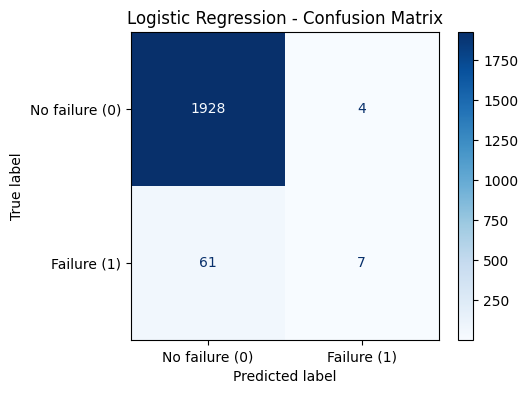

True negative (doğru 'arıza yok')    1928
False positive (yanlış alarm)           4
False negative (kaçırılan arıza)       61
True positive (yakalanan arıza)         7
dtype: int64

In [10]:
# Confusion matrix: satırlar gerçek sınıf, sütunlar tahmin edilen sınıf.
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["No failure (0)", "Failure (1)"]).plot(
    ax=ax, cmap="Blues", values_format="d"
)
ax.set_title("Logistic Regression - Confusion Matrix")
plt.show()

pd.Series({
    "True negative (doğru 'arıza yok')": tn,
    "False positive (yanlış alarm)": fp,
    "False negative (kaçırılan arıza)": fn,
    "True positive (yakalanan arıza)": tp,
})

In [11]:
# Arıza sınıfı (1) için metrikler.
# zero_division=0: model hiç '1' tahmin etmezse precision 0/0 olur; bunu 0 kabul ediyoruz.
lr_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision (failure)": precision_score(y_test, y_pred, zero_division=0),
    "recall (failure)": recall_score(y_test, y_pred, zero_division=0),
    "f1 (failure)": f1_score(y_test, y_pred, zero_division=0),
}
pd.Series(lr_metrics).round(4)

accuracy               0.9675
precision (failure)    0.6364
recall (failure)       0.1029
f1 (failure)           0.1772
dtype: float64

In [12]:
print(classification_report(
    y_test, y_pred, target_names=["No failure (0)", "Failure (1)"], digits=4, zero_division=0
))

                precision    recall  f1-score   support

No failure (0)     0.9693    0.9979    0.9834      1932
   Failure (1)     0.6364    0.1029    0.1772        68

      accuracy                         0.9675      2000
     macro avg     0.8028    0.5504    0.5803      2000
  weighted avg     0.9580    0.9675    0.9560      2000



## Dummy Baseline ile Karşılaştırma

In [13]:
# Her kayıt için her zaman 'arıza yok' (0) diyen naif model; aynı eğitim/test ayrımı.
dummy = DummyClassifier(strategy="constant", constant=0)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

# Precision = 0: hiç arıza tahmini yok (0/0 -> 0).
# Recall = 0: gerçek arızaların hiçbiri yakalanmadı.
dummy_metrics = {
    "accuracy": accuracy_score(y_test, y_pred_dummy),
    "precision (failure)": precision_score(y_test, y_pred_dummy, zero_division=0),
    "recall (failure)": recall_score(y_test, y_pred_dummy, zero_division=0),
    "f1 (failure)": f1_score(y_test, y_pred_dummy, zero_division=0),
}

In [14]:
# Aynı test kümesinde iki modelin karşılaştırması.
comparison = pd.DataFrame(
    {"Dummy (always 0)": dummy_metrics, "Logistic Regression": lr_metrics}
).T.round(4)

comparison["failures caught"] = [
    int(((y_pred_dummy == 1) & (y_test == 1)).sum()), int(tp)
]
comparison["false alarms"] = [
    int(((y_pred_dummy == 1) & (y_test == 0)).sum()), int(fp)
]
comparison

,accuracy,precision (failure),recall (failure),f1 (failure),failures caught,false alarms
Dummy (always 0),0.9660,0.0000,0.0000,0.0000,0,0
Logistic Regression,0.9675,0.6364,0.1029,0.1772,7,4


StandardScaler: Sayısal değerleri benzer ölçeğe getirir.
Örneğin sıcaklık 20, tork 50 gibi farklı aralıklardaki değerleri ortalaması 0, standart sapması 1 olacak şekilde dönüştürür. Logistic Regression’ın daha dengeli öğrenmesini sağlar.

OneHotEncoder: Kategorik metinleri sayısal sütunlara çevirir. Böylece model metinleri anlayabilir.

SimpleImputer: Eksik değerleri doldurur.
Sayısal değerlerde genellikle medyanı, kategorik değerlerde en sık görülen değeri kullanır.

ColumnTransformer: Farklı sütunlara farklı işlemler uygular.
Sayısal sütunlara StandardScaler, kategorik sütunlara OneHotEncoder uygular.